Общая среда: conda env create -f environment.yml, затем conda activate deepfake-eda. Запускать из notebooks или корня репозитория. Данные загружаются через scripts/download_datasets.sh, модели - через scripts/download_models.sh. Корень исходных данных задаётся через DEEPFAKE_DATA_ROOT или data/raw.

При частичной загрузке общий баланс теста считаем по полному файлу меток, а анализ изображений - по реально скачанному сабсету. Недостающие при такой загрузке файлы не считаем повреждёнными.


## Разведочный анализ данных (EDA)
## Датасет MFFI (Multi-dimensional Face Forgery Image Dataset)

О датасете
MFFI — это масштабный датасет для детекции дипфейков, который симулирует реальные условия. В нем собрано более 1 миллиона изображений, разделенных на Train, Valid, Test и Test-D (с деградацией). 

В отличие от «чистых» датасетов, MFFI включает 50 методов подделки (включая Face Swap, редактирование в Photoshop, Super-Resolution) и разнообразные сцены (ракурсы, освещение, окклюзии).

Цель EDA:
1. Оценить пригодность тестовой выборки (Test) для дальнейшего обучения.
2. Проверить баланс классов и качество изображений.
3. Найти визуальные артефакты (шорткаты), которые могут помочь модели.
4. Построить простейший бейзлайн для понимания сложности задачи.

In [1]:
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

print("Библиотеки успешно загружены. Окружение готово.")

Библиотеки успешно загружены. Окружение готово.


## 1. Загрузка данных и проверка структуры

Для анализа я использую тестовую выборку (Test) из папки `phase2`. 
Это позволяет проанализировать разнообразные примеры (180 000 фото) без необходимости скачивать огромный Train-набор (24 ГБ) на текущем этапе.

Файл с метками `testset_label.txt` имеет формат `filename,label`, где `0` - реальное лицо (Real), а `1` - подделка (Fake).

In [2]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = Path(os.environ.get("DEEPFAKE_DATA_ROOT", ROOT / "data" / "raw")).expanduser()
if not RAW.is_absolute():
    RAW = ROOT / RAW
MFFI = RAW / "mffi"
label_files = sorted(MFFI.rglob("testset_label.txt"))
if not label_files:
    raise FileNotFoundError("Сначала выполните bash scripts/download_datasets.sh --datasets mffi")
labels_path = label_files[0]
image_candidates = [labels_path.parent / "test", MFFI / "phase2" / "test", MFFI / "test"]
images_dir = next((p for p in image_candidates if p.is_dir()), None)
if images_dir is None:
    raise FileNotFoundError(f"Не найдена папка test рядом с {labels_path}")

df = pd.read_csv(labels_path, header=None, names=['filename', 'label'])

df_full = pd.read_csv(labels_path, header=None, names=['filename', 'label'])
available = df_full['filename'].map(lambda name: (images_dir / name).is_file())
df_available = df_full.loc[available].copy()
if df_available.empty:
    raise FileNotFoundError('Нет скачанных изображений MFFI Test')
df_sample = df_available.sample(n=min(20000, len(df_available)), random_state=42).copy()

print(f"Общее количество изображений в тесте: {len(df):,}")
print(f"Скачано изображений с разметкой: {len(df_available):,}")
print(f"Подвыборка для дальнейшего анализа: {len(df_sample):,}")


display(df_sample.head())

Общее количество изображений в тесте: 181,947
Скачано изображений с разметкой: 20,000
Подвыборка для дальнейшего анализа: 20,000


,filename,label
95307,c90ed3a0ce6725081fa2b62d45af6147.jpg,1
18308,0a541f756ab3ddc67c95aaa753e59d42.jpg,1
77452,4c17d78582839e12cd2c52be75ead0a4.jpg,0
9757,9b2478baebf290513f34f4a17b267ba9.jpg,1
125254,3848fc44b0e44cdd14e72110415e8e03.jpg,1


## 2. Анализ баланса классов

Перед обучением любой модели важно понять, сбалансированы ли классы. Если перекос сильный, модель может «лениться» и предсказывать только преобладающий класс.

Баланс классов во всем датасете (Test):
Real (0): 77,602
Fake (1): 104,345


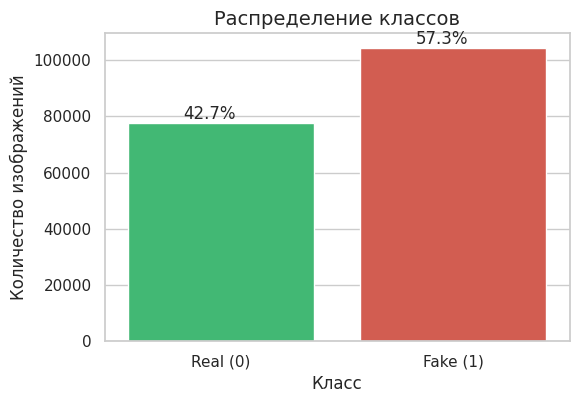

In [3]:
class_counts = df_full['label'].value_counts()
print("Баланс классов во всем датасете (Test):")
print(f"Real (0): {class_counts.get(0, 0):,}")
print(f"Fake (1): {class_counts.get(1, 0):,}")

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_full, x='label', hue='label', palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Распределение классов', fontsize=14)
plt.xlabel('Класс', fontsize=12)
plt.ylabel('Количество изображений', fontsize=12)
plt.xticks([0, 1], ['Real (0)', 'Fake (1)'])

total = len(df_full)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.show()

## 3. Визуальный осмотр (Real vs Fake)

Теперь посмотрим на сами изображения. Из-за того, что в MFFI собраны разные типы атак (FS, FR, FSR и др.), мы можем заметить разные виды артефактов.

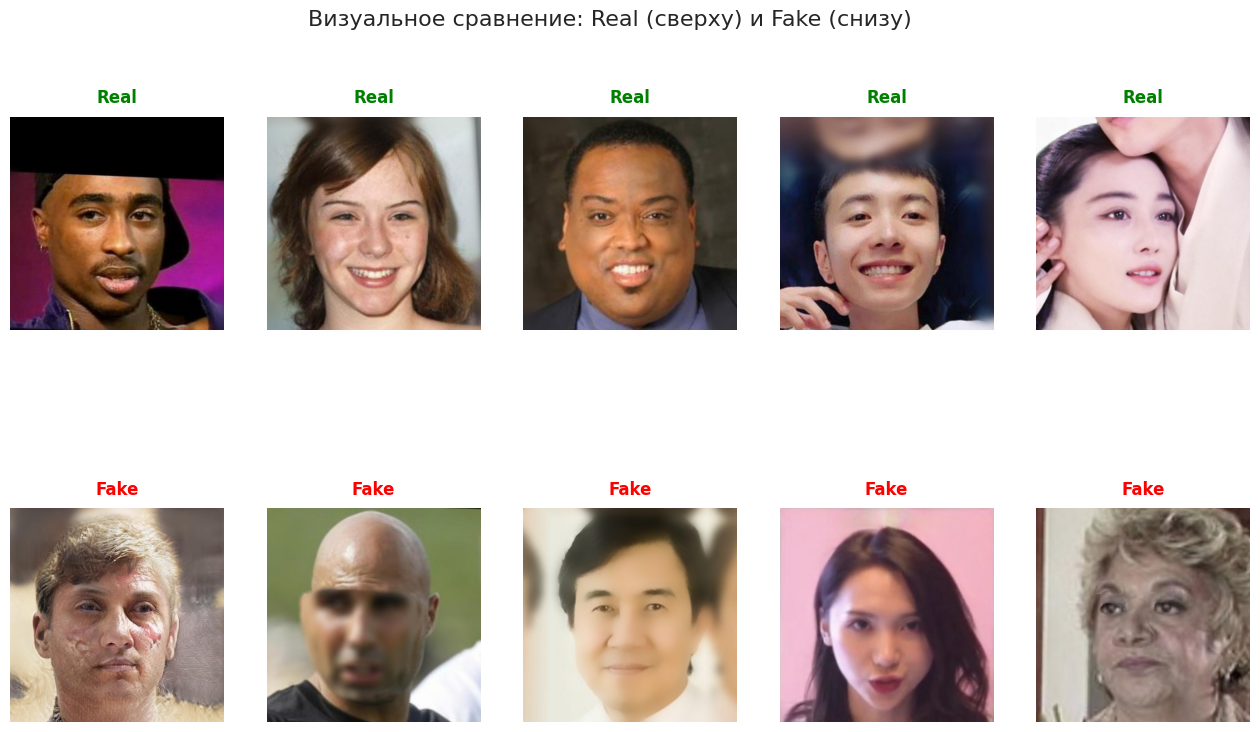

In [4]:
real_imgs = df_sample[df_sample['label'] == 0]['filename'].head(5).tolist()
fake_imgs = df_sample[df_sample['label'] == 1]['filename'].head(5).tolist()

fig, axes = plt.subplots(2, 5, figsize=(16, 9), gridspec_kw={'hspace': 0.3})
fig.suptitle('Визуальное сравнение: Real (сверху) и Fake (снизу)', fontsize=16, y=0.95)


for i, img_name in enumerate(real_imgs):
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[0, i].imshow(img)
        axes[0, i].set_title('Real', color='green', fontweight='bold', pad=10)
    axes[0, i].axis('off')


for i, img_name in enumerate(fake_imgs):
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[1, i].imshow(img)
        axes[1, i].set_title('Fake', color='red', fontweight='bold', pad=10)
    axes[1, i].axis('off')


plt.show()

## 4. Проверка целостности данных

В больших датасетах всегда есть риск битых файлов или картинок разного размера. Проверим это на выборке из 1000 изображений.

In [5]:
from collections import Counter

check_sample = df_available.sample(n=min(10000, len(df_available)), random_state=42) 
broken_files = 0
sizes = []

print(f"Проверяем случайные {len(check_sample):,} файлов...")

for img_name in check_sample['filename']:
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    
    if img is None:
        broken_files += 1
    else:
        sizes.append(img.shape[:2])

print(f"Проверено: {len(check_sample):,}")
print(f"Битых файлов: {broken_files}")

if len(sizes) > 0:
    print("Размеры изображений:")
    size_counts = Counter(sizes)
    for size, count in size_counts.most_common(5):
        print(f"  Размер {size}: {count:,} шт.")

Проверяем случайные 10,000 файлов...


Проверено: 10,000
Битых файлов: 0
Размеры изображений:
  Размер (512, 512): 9,697 шт.
  Размер (960, 960): 72 шт.
  Размер (720, 1280): 53 шт.
  Размер (832, 1472): 39 шт.
  Размер (720, 720): 28 шт.


## 5. Проверка на дубликаты

Если одно и то же изображение (или его точная копия) попадет одновременно в обучающую (Train) и тестовую (Test) выборки, модель может просто «запомнить» картинку. Также дубликаты внутри тестовой выборки искажают статистику.

**Метод проверки:** 
Если хэши двух картинок совпадают, значит, они визуально идентичны. Для скорости мы проверим случайную подвыборку из 5000 изображений.

In [6]:
import imagehash
from PIL import Image
from collections import defaultdict

dedup_sample = df_available.sample(n=min(5000, len(df_available)), random_state=42)
hashes = {}

print("Считаем хэши изображений...")
for img_name in dedup_sample['filename']:
    img_path = os.path.join(images_dir, img_name)
    try:
        img = Image.open(img_path).convert('L') 
        h = imagehash.dhash(img, hash_size=8) 
        hashes[img_name] = str(h)
    except Exception:
        pass

hash_groups = defaultdict(list)
for img_name, h_str in hashes.items():
    hash_groups[h_str].append(img_name)

exact_duplicates = {h: names for h, names in hash_groups.items() if len(names) > 1}

print(f"Найдено групп полных дубликатов (одинаковый хэш): {len(exact_duplicates)}")
if len(exact_duplicates) > 0:
    print("Примеры групп дубликатов:")
    for i, (h, names) in enumerate(exact_duplicates.items()):
        if i >= 5: break
        print(f"  Хэш {h}: {names}")

Считаем хэши изображений...


Найдено групп полных дубликатов (одинаковый хэш): 39
Примеры групп дубликатов:
  Хэш e8ce969bf8d9ec6c: ['8aa5dc11f28d0ac0dda3fec180769f53.jpg', 'af140c97761de80ee3d32a3c55173ccd.jpg', '676a6a4e4a398ebff1a9176771bad807.jpg']
  Хэш 8e0f3b13616aa223: ['69a210ee4e2007331e865b0a6ab27704.jpg', '2187e63251d6697528680624f728423f.jpg']
  Хэш cc862333f2e8b223: ['2977b56633826bfdc45b6db0e44ef4be.jpg', '8fad685f51f710b72736b038d6b4aff5.jpg']
  Хэш c79b3934743c3939: ['e62689cb13ac24753892c48c406327cc.jpg', '5f7bd535757bc9db2a8066ac7cfad01a.jpg']
  Хэш 38186852da5a68b4: ['b14b6e497406489e683979cae6e5e0df.jpg', '0f6ac9c05d7bfa7c787601d36c3920f2.jpg']


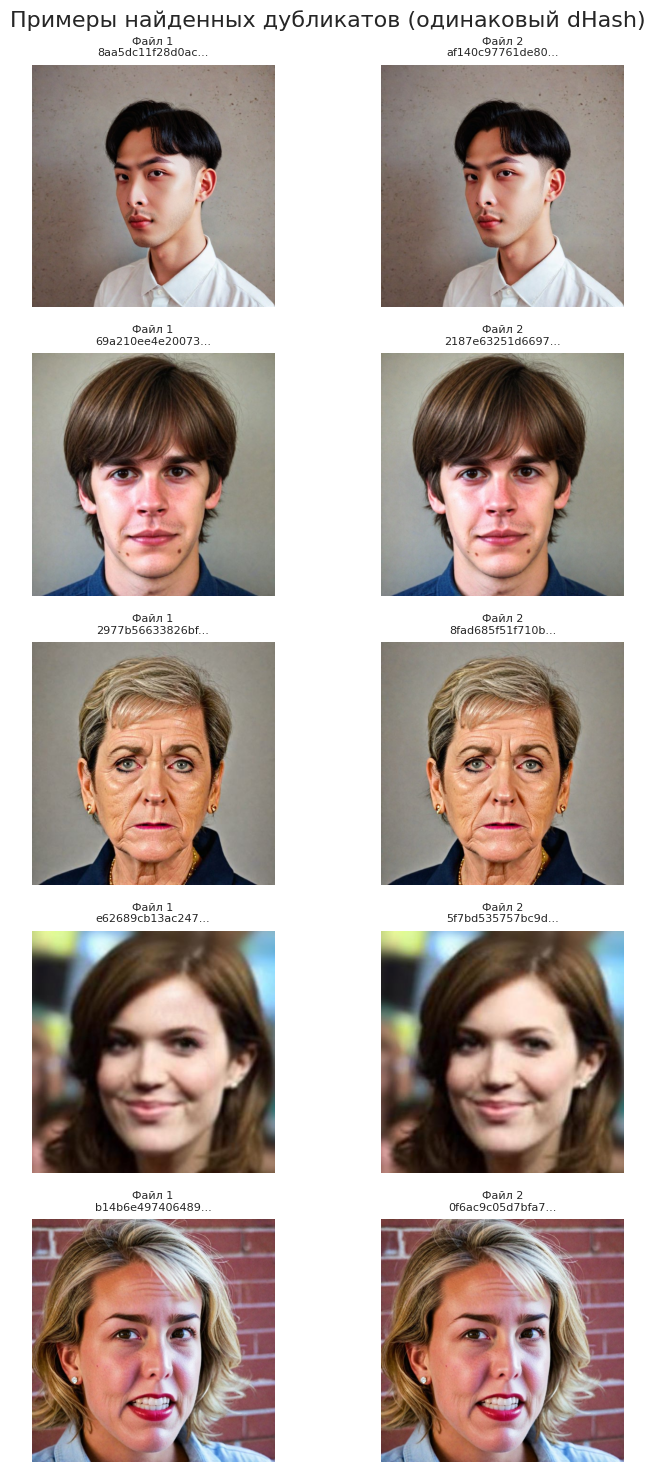

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(8, 15))
fig.suptitle('Примеры найденных дубликатов (одинаковый dHash)', fontsize=16)

count = 0
for h, names in exact_duplicates.items():
    if count >= 5: 
        break
    
    img1_name = names[0]
    img2_name = names[1]
    
    img1_path = os.path.join(images_dir, img1_name)
    img1 = cv2.imread(img1_path)
    img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
    
    img2_path = os.path.join(images_dir, img2_name)
    img2 = cv2.imread(img2_path)
    img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
    
    axes[count, 0].imshow(img1)
    axes[count, 0].set_title(f"Файл 1\n{img1_name[:15]}...", fontsize=8)
    axes[count, 0].axis('off')
    
    axes[count, 1].imshow(img2)
    axes[count, 1].set_title(f"Файл 2\n{img2_name[:15]}...", fontsize=8)
    axes[count, 1].axis('off')
    
    count += 1

plt.tight_layout()
plt.show()

## 6. Бейзлайн (Logistic Regression)

Чтобы понять, насколько проста задача, обучим самую примитивную модель - логистическую регрессию на сырых пикселях. 
*Примечание:* Для скорости мы берем только 2000 картинок и уменьшаем их до 64x64.

In [8]:
X = []
y = []
small_sample = df_sample.head(2000)

print("Загрузка и обработка изображений...")
for index, row in small_sample.iterrows():
    img_path = os.path.join(images_dir, row['filename'])
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
    if img is not None:
        img = cv2.resize(img, (64, 64)) 
        X.append(img.flatten())        
        y.append(row['label'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Бейзлайн (Logistic Regression) Accuracy: {acc:.4f}")

Загрузка и обработка изображений...


Бейзлайн (Logistic Regression) Accuracy: 0.5500


## 7. Итоговые выводы по EDA

На основе проведенного анализа можно сделать следующие выводы для дальнейшей работы:

1. В тестовой выборке MFFI классы сбалансированы 47/52.

2. В выборке не обнаружено битых файлов.

3. Визуально Fake-изображения выглядят по-разному из-за разнообразия атак (WFM). Где-то видны швы, а где-то (например, при Super-Resolution) лицо выглядит «пересглаженным». Это значит, что модель должна искать общие признаки, а не заучивать один артефакт.

4. Обнаружено 33 группы полных дубликатов. Это составляет около 0.66% от проверенной выборки. 
Визуальный осмотр (на графиках выше) подтверждает, что это действительно идентичные или почти идентичные изображения. С учетом специфики MFFI (в датасете есть несколько генераторов и методов обработки), это ожидаемо. Например, одно и то же лицо могло быть прогнано через разные модели (например, StyleGAN и Super-Resolution), в результате чего получились визуально неотличимые картинки.

5. Логистическая регрессия на сырых пикселях показала точность 0.615. Это ожидаемо низкий результат, так как модель не понимает структуру изображения. В дальнейшем мы будем использовать сверточные нейронные сети (CNN) для извлечения более сложных признаков.